# 05 - Outlier Detection

This notebook identifies statistical outliers in the county-level EV dataset using four methods:
IQR analysis, Z-score thresholding, Isolation Forest, and Local Outlier Factor (LOF).

Primary question: Is King County a formal statistical outlier or simply the largest urban county?
Secondary question: Which other counties deviate unexpectedly from their cluster peers?

Input: county_features.csv, county_scaled.csv, county_clustered.csv
Output: outlier_counties.csv + four figures

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Output directories
import os
os.makedirs('outputs/figures', exist_ok=True)
os.makedirs('outputs/results', exist_ok=True)

plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.family'] = 'sans-serif'

print("Libraries loaded.")

Libraries loaded.


In [2]:
# Load county-level feature, scaled, and clustered datasets
county_features = pd.read_csv('outputs/results/county_features.csv')
county_scaled = pd.read_csv('outputs/results/county_scaled.csv')
county_clustered = pd.read_csv('outputs/results/county_clustered.csv')

# Cluster label mapping consistent with previous modules
cluster_labels = {
    0: 'Low Adoption BEV',
    1: 'Low Adoption PHEV',
    2: 'High Adoption',
    3: 'King County Mega Hub'
}
county_clustered['Cluster_Label'] = county_clustered['Cluster'].map(cluster_labels)

print(f"county_features shape: {county_features.shape}")
print(f"county_scaled shape:   {county_scaled.shape}")
print(f"county_clustered shape: {county_clustered.shape}")
print(f"\nCluster distribution:")
print(county_clustered['Cluster_Label'].value_counts())
print(f"\nColumns in county_features:\n{county_features.columns.tolist()}")

county_features shape: (246, 11)
county_scaled shape:   (246, 11)
county_clustered shape: (246, 13)

Cluster distribution:
Cluster_Label
Low Adoption BEV        156
Low Adoption PHEV        59
High Adoption            30
King County Mega Hub      1
Name: count, dtype: int64

Columns in county_features:
['County', 'Total_EVs', 'BEV_Count', 'PHEV_Count', 'Avg_Electric_Range', 'Unique_Makes', 'Unique_Models', 'Most_Common_Make', 'Avg_Model_Year', 'BEV_Proportion', 'PHEV_Proportion']


In [3]:
# Define the numeric features to run IQR analysis on
numeric_cols = [
    'Total_EVs', 'BEV_Count', 'PHEV_Count', 'Avg_Electric_Range',
    'Unique_Makes', 'Unique_Models', 'Avg_Model_Year',
    'BEV_Proportion', 'PHEV_Proportion'
]

# Compute IQR bounds for each feature and flag counties beyond 1.5x IQR
iqr_results = {}
for col in numeric_cols:
    Q1 = county_features[col].quantile(0.25)
    Q3 = county_features[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = county_features[(county_features[col] < lower) | (county_features[col] > upper)]['County'].tolist()
    iqr_results[col] = {'Q1': Q1, 'Q3': Q3, 'IQR': IQR, 'Lower': lower, 'Upper': upper, 'Outlier_Count': len(outliers), 'Outliers': outliers}

# Summarize IQR results
print("IQR Outlier Summary (1.5x IQR rule):")
print(f"{'Feature':<22} {'Lower':>10} {'Upper':>10} {'Outliers':>9}")
print("-" * 55)
for col, v in iqr_results.items():
    print(f"{col:<22} {v['Lower']:>10.2f} {v['Upper']:>10.2f} {v['Outlier_Count']:>9}")

# Identify counties flagged as outliers on Total_EVs specifically
total_evs_outliers = county_features[county_features['Total_EVs'] > iqr_results['Total_EVs']['Upper']][['County', 'Total_EVs']].sort_values('Total_EVs', ascending=False)
print(f"\nCounties flagged as IQR outliers on Total_EVs:")
print(total_evs_outliers.to_string(index=False))

IQR Outlier Summary (1.5x IQR rule):
Feature                     Lower      Upper  Outliers
-------------------------------------------------------
Total_EVs                   -5.00      11.00        47
BEV_Count                   -3.50       8.50        46
PHEV_Count                  -3.00       5.00        40
Avg_Electric_Range         -73.64     122.73        24
Unique_Makes                -3.50       8.50        41
Unique_Models               -4.62      10.38        42
Avg_Model_Year            2017.91    2026.06         9
BEV_Proportion               0.02       1.59        25
PHEV_Proportion             -0.59       0.98        25

Counties flagged as IQR outliers on Total_EVs:
      County  Total_EVs
        King     133815
   Snohomish      33766
      Pierce      22238
       Clark      16694
    Thurston       9911
      Kitsap       9116
     Spokane       7652
     Whatcom       6664
      Benton       3827
      Skagit       3194
      Island       2979
      Yakima       18

In [4]:
# Compute Z-scores for all numeric features across all counties
z_scores = pd.DataFrame(
    stats.zscore(county_features[numeric_cols]),
    columns=numeric_cols,
    index=county_features.index
)
z_scores['County'] = county_features['County'].values

# Flag counties with |z| > 3.0 on any feature
z_scores['Max_Abs_Z'] = z_scores[numeric_cols].abs().max(axis=1)
z_scores['Flagged_Features'] = z_scores[numeric_cols].apply(
    lambda row: [col for col in numeric_cols if abs(row[col]) > 3.0], axis=1
)
z_scores['Num_Flagged'] = z_scores['Flagged_Features'].apply(len)

# Show counties flagged on at least one feature
z_outliers = z_scores[z_scores['Num_Flagged'] > 0][['County', 'Max_Abs_Z', 'Num_Flagged', 'Flagged_Features']].sort_values('Max_Abs_Z', ascending=False)

print(f"Counties flagged by Z-score (|z| > 3.0 on any feature): {len(z_outliers)}")
print()
print(z_outliers.to_string(index=False))

# Print King County's full Z-score profile specifically
king_z = z_scores[z_scores['County'] == 'King'][numeric_cols].T
king_z.columns = ['Z-Score']
print(f"\nKing County Z-score profile:")
print(king_z.round(2).to_string())

Counties flagged by Z-score (|z| > 3.0 on any feature): 20

    County  Max_Abs_Z  Num_Flagged                                                Flagged_Features
      King  14.793182            5 [Total_EVs, BEV_Count, PHEV_Count, Unique_Makes, Unique_Models]
 Penobscot   4.921073            1                                                [Avg_Model_Year]
 Lexington   4.098294            1                                            [Avg_Electric_Range]
 Snohomish   3.984413            5 [Total_EVs, BEV_Count, PHEV_Count, Unique_Makes, Unique_Models]
    Pierce   3.852606            1                                                 [Unique_Models]
   Bannock   3.833028            1                                            [Avg_Electric_Range]
Bernalillo   3.833028            1                                            [Avg_Electric_Range]
     Clark   3.826245            2                                   [Unique_Makes, Unique_Models]
      Yolo   3.442930            1               

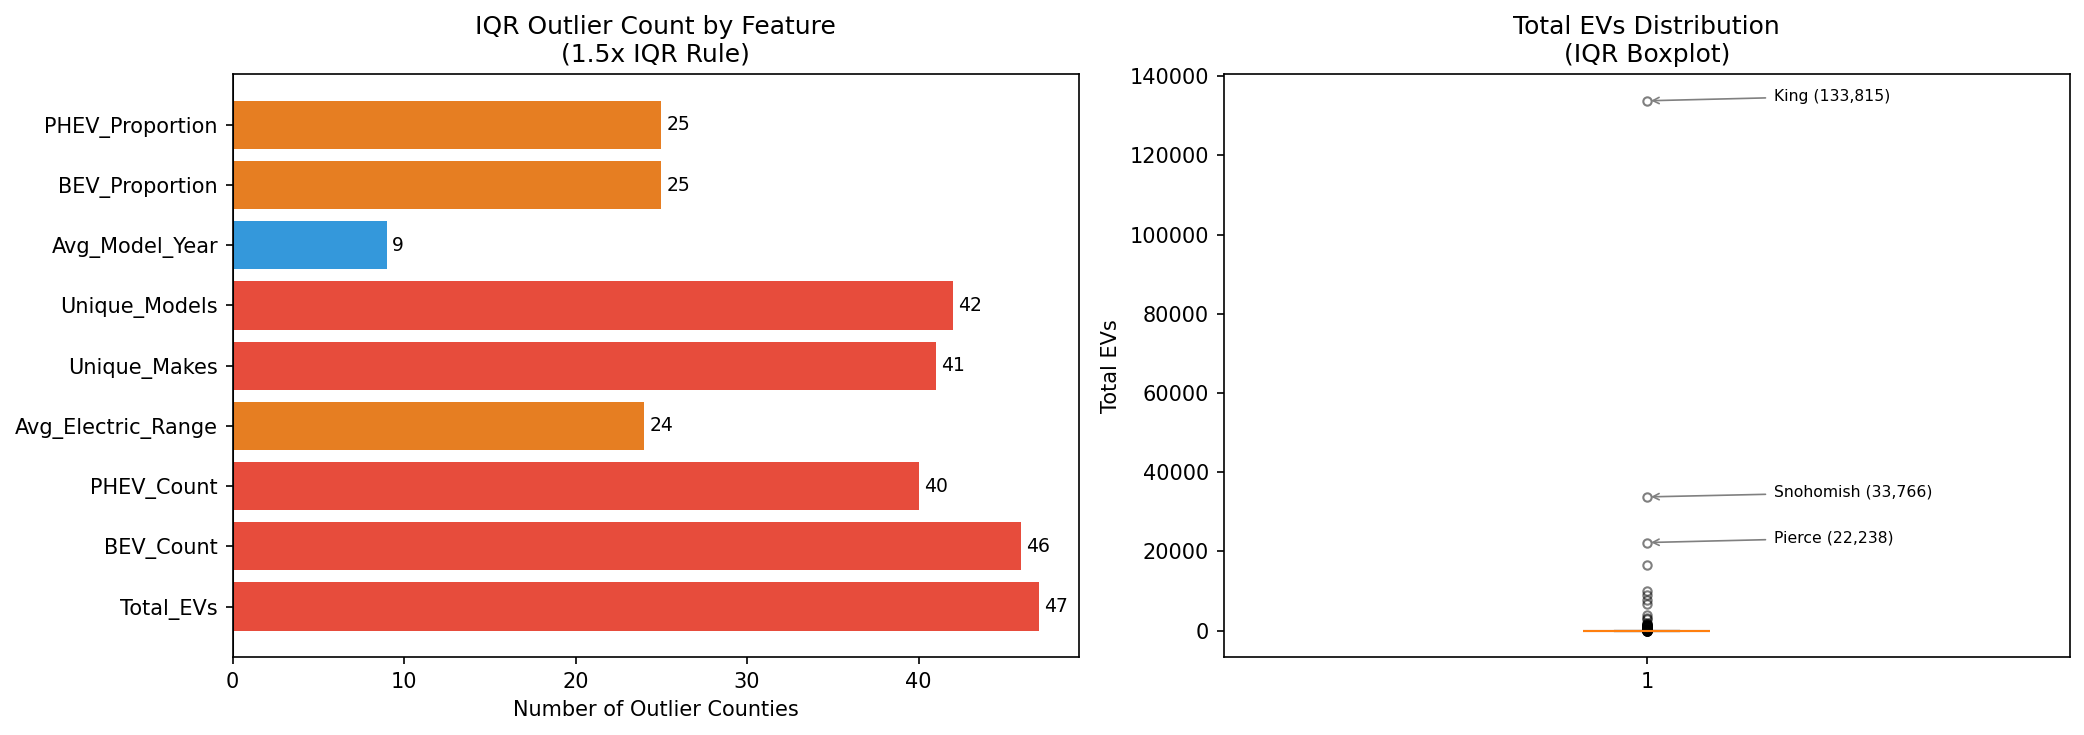

Figure saved: outlier_iqr.png


In [5]:
# Visualize IQR outlier counts per feature as a horizontal bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: number of outliers per feature
outlier_counts = {col: iqr_results[col]['Outlier_Count'] for col in numeric_cols}
colors = ['#e74c3c' if v > 30 else '#e67e22' if v > 15 else '#3498db' for v in outlier_counts.values()]
axes[0].barh(list(outlier_counts.keys()), list(outlier_counts.values()), color=colors)
axes[0].set_xlabel('Number of Outlier Counties')
axes[0].set_title('IQR Outlier Count by Feature\n(1.5x IQR Rule)')
axes[0].axvline(x=0, color='black', linewidth=0.5)
for i, v in enumerate(outlier_counts.values()):
    axes[0].text(v + 0.3, i, str(v), va='center', fontsize=9)

# Right plot: Total_EVs distribution with IQR fence and top counties labeled
axes[1].boxplot(county_features['Total_EVs'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='#3498db', alpha=0.6),
                flierprops=dict(marker='o', color='#e74c3c', alpha=0.5, markersize=4))
axes[1].set_ylabel('Total EVs')
axes[1].set_title('Total EVs Distribution\n(IQR Boxplot)')

# Annotate top 3 outliers
for _, row in total_evs_outliers.head(3).iterrows():
    axes[1].annotate(f"{row['County']} ({row['Total_EVs']:,})",
                     xy=(1, row['Total_EVs']),
                     xytext=(1.15, row['Total_EVs']),
                     fontsize=7.5,
                     arrowprops=dict(arrowstyle='->', color='gray', lw=0.8))

plt.tight_layout()
plt.savefig('outputs/figures/outlier_iqr.png', bbox_inches='tight')
plt.show()
print("Figure saved: outlier_iqr.png")

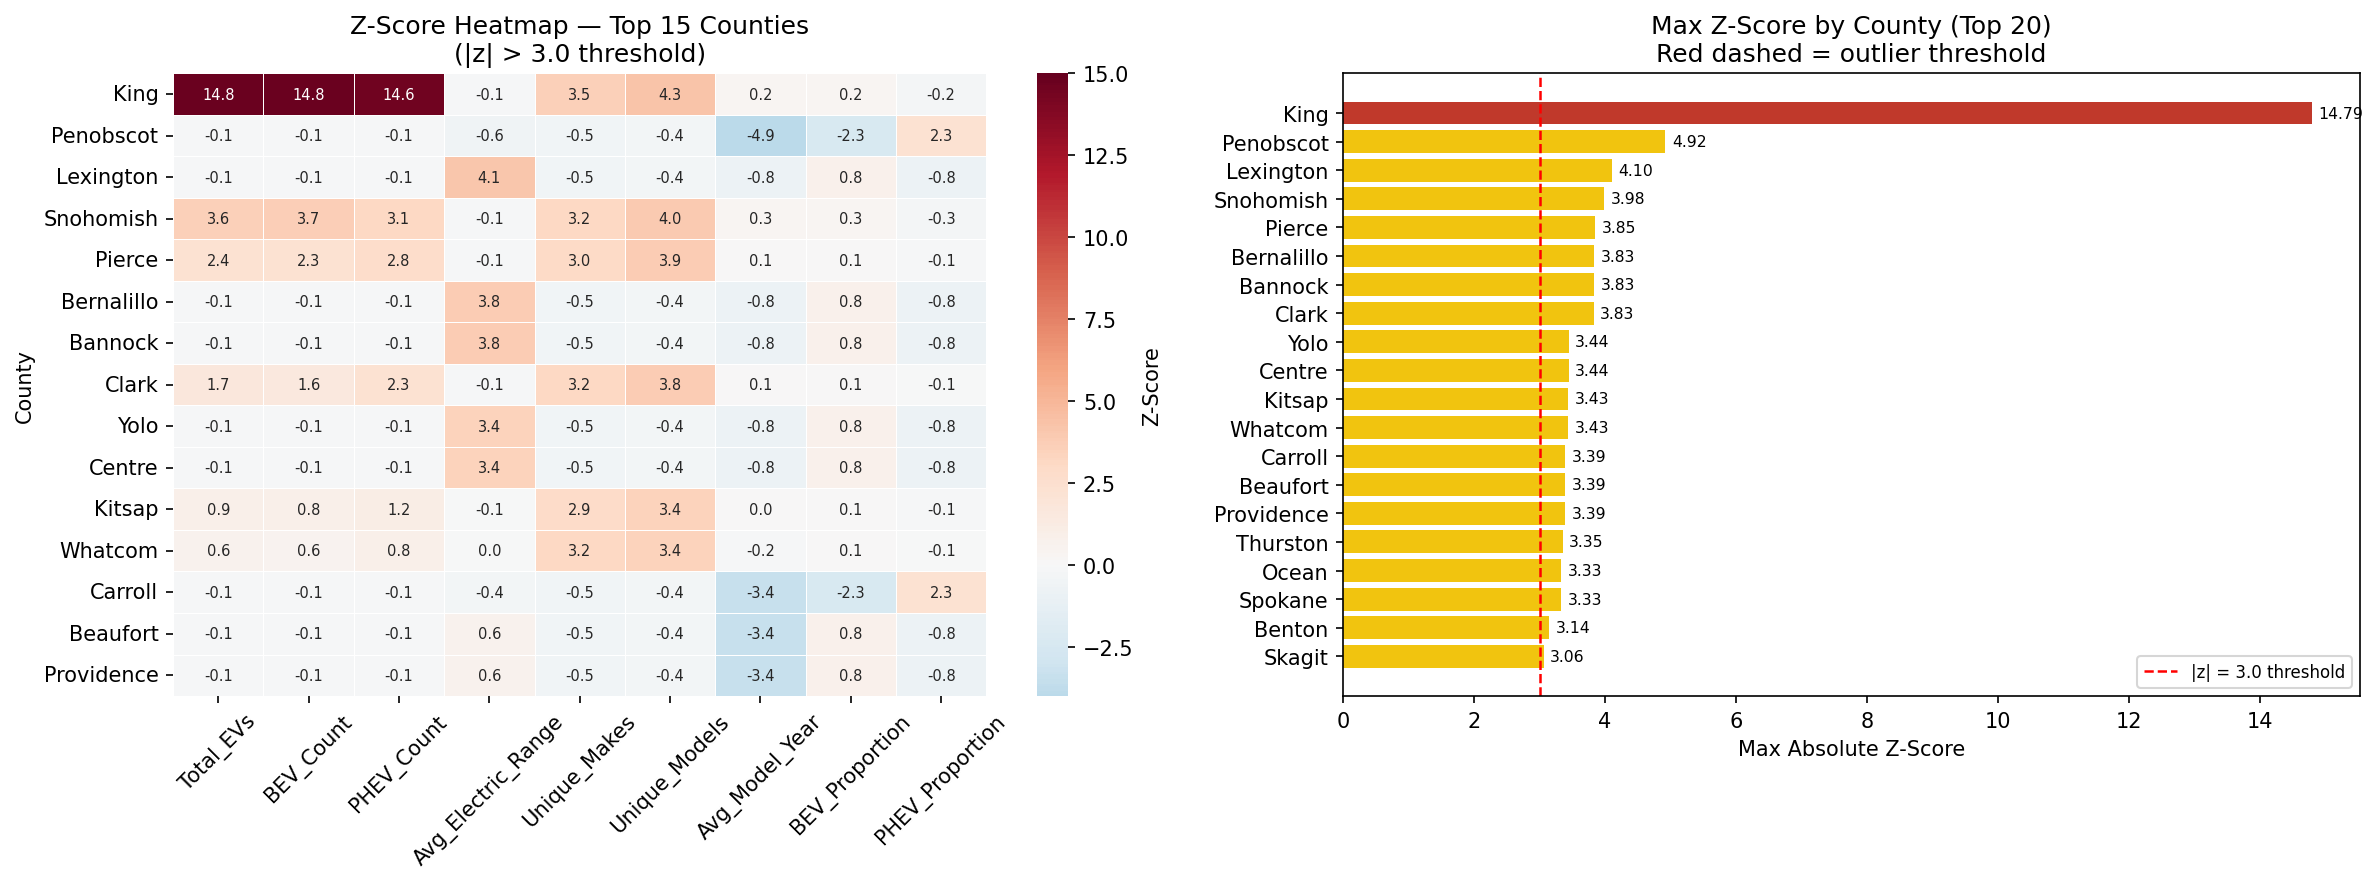

Figure saved: outlier_zscore.png


In [6]:
# Build a heatmap of Z-scores for the top flagged counties
top_counties = z_scores.sort_values('Max_Abs_Z', ascending=False).head(15)['County'].tolist()
z_heatmap = z_scores[z_scores['County'].isin(top_counties)].set_index('County')[numeric_cols]
z_heatmap = z_heatmap.loc[top_counties]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left plot: Z-score heatmap for top 15 flagged counties
sns.heatmap(z_heatmap, ax=axes[0], cmap='RdBu_r', center=0, vmin=-4, vmax=15,
            annot=True, fmt='.1f', linewidths=0.4, cbar_kws={'label': 'Z-Score'},
            annot_kws={'size': 7})
axes[0].set_title('Z-Score Heatmap — Top 15 Counties\n(|z| > 3.0 threshold)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=45)
axes[0].tick_params(axis='y', rotation=0)

# Right plot: Max Z-score per county (top 20), colored by severity
top20_z = z_scores.sort_values('Max_Abs_Z', ascending=False).head(20)
colors_z = ['#c0392b' if z > 10 else '#e67e22' if z > 5 else '#f1c40f' if z > 3 else '#3498db'
            for z in top20_z['Max_Abs_Z']]
axes[1].barh(top20_z['County'][::-1], top20_z['Max_Abs_Z'][::-1], color=colors_z[::-1])
axes[1].axvline(x=3.0, color='red', linestyle='--', linewidth=1.2, label='|z| = 3.0 threshold')
axes[1].set_xlabel('Max Absolute Z-Score')
axes[1].set_title('Max Z-Score by County (Top 20)\nRed dashed = outlier threshold')
axes[1].legend(fontsize=8)
for i, (_, row) in enumerate(top20_z[::-1].iterrows()):
    axes[1].text(row['Max_Abs_Z'] + 0.1, i, f"{row['Max_Abs_Z']:.2f}", va='center', fontsize=7.5)

plt.tight_layout()
plt.savefig('outputs/figures/outlier_zscore.png', bbox_inches='tight')
plt.show()
print("Figure saved: outlier_zscore.png")

In [7]:
# Build feature matrix from scaled data for unsupervised anomaly detection
X = county_scaled[numeric_cols].values

# Fit Isolation Forest — contamination=0.05 means we expect ~5% of counties to be anomalies
iso_forest = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)
iso_labels = iso_forest.fit_predict(X)
iso_scores = iso_forest.decision_function(X)

# Negative anomaly score = more anomalous; convert so higher = more anomalous
county_features['IF_Score'] = -iso_scores
county_features['IF_Outlier'] = iso_labels == -1

# Summarize results
n_outliers = county_features['IF_Outlier'].sum()
print(f"Isolation Forest flagged {n_outliers} counties as anomalies ({n_outliers/len(county_features)*100:.1f}%)")
print()

# Show all flagged counties sorted by anomaly score
if_outliers = county_features[county_features['IF_Outlier']][['County', 'Total_EVs', 'BEV_Proportion', 'Avg_Electric_Range', 'Unique_Makes', 'IF_Score']].sort_values('IF_Score', ascending=False)
print("Flagged counties (most anomalous first):")
print(if_outliers.to_string(index=False))

# Check if King County is flagged
king_flagged = county_features[county_features['County'] == 'King']['IF_Outlier'].values[0]
king_score = county_features[county_features['County'] == 'King']['IF_Score'].values[0]
print(f"\nKing County — Flagged: {king_flagged} | Anomaly Score: {king_score:.4f}")

Isolation Forest flagged 13 counties as anomalies (5.3%)

Flagged counties (most anomalous first):
    County  Total_EVs  BEV_Proportion  Avg_Electric_Range  Unique_Makes  IF_Score
      King     133815          0.8183               38.69            44  0.276917
 Snohomish      33766          0.8398               36.15            40  0.166998
    Pierce      22238          0.7824               39.76            38  0.102333
     Clark      16694          0.7576               39.91            40  0.083940
 Penobscot          1          0.0000                6.00             1  0.069786
Burlington          2          0.0000               30.00             2  0.065484
   Spokane       7652          0.7162               37.94            38  0.052399
   Whatcom       6664          0.7586               45.84            40  0.037324
  Thurston       9911          0.7705               42.91            37  0.032556
    Kitsap       9116          0.7666               41.78            37  0.021747

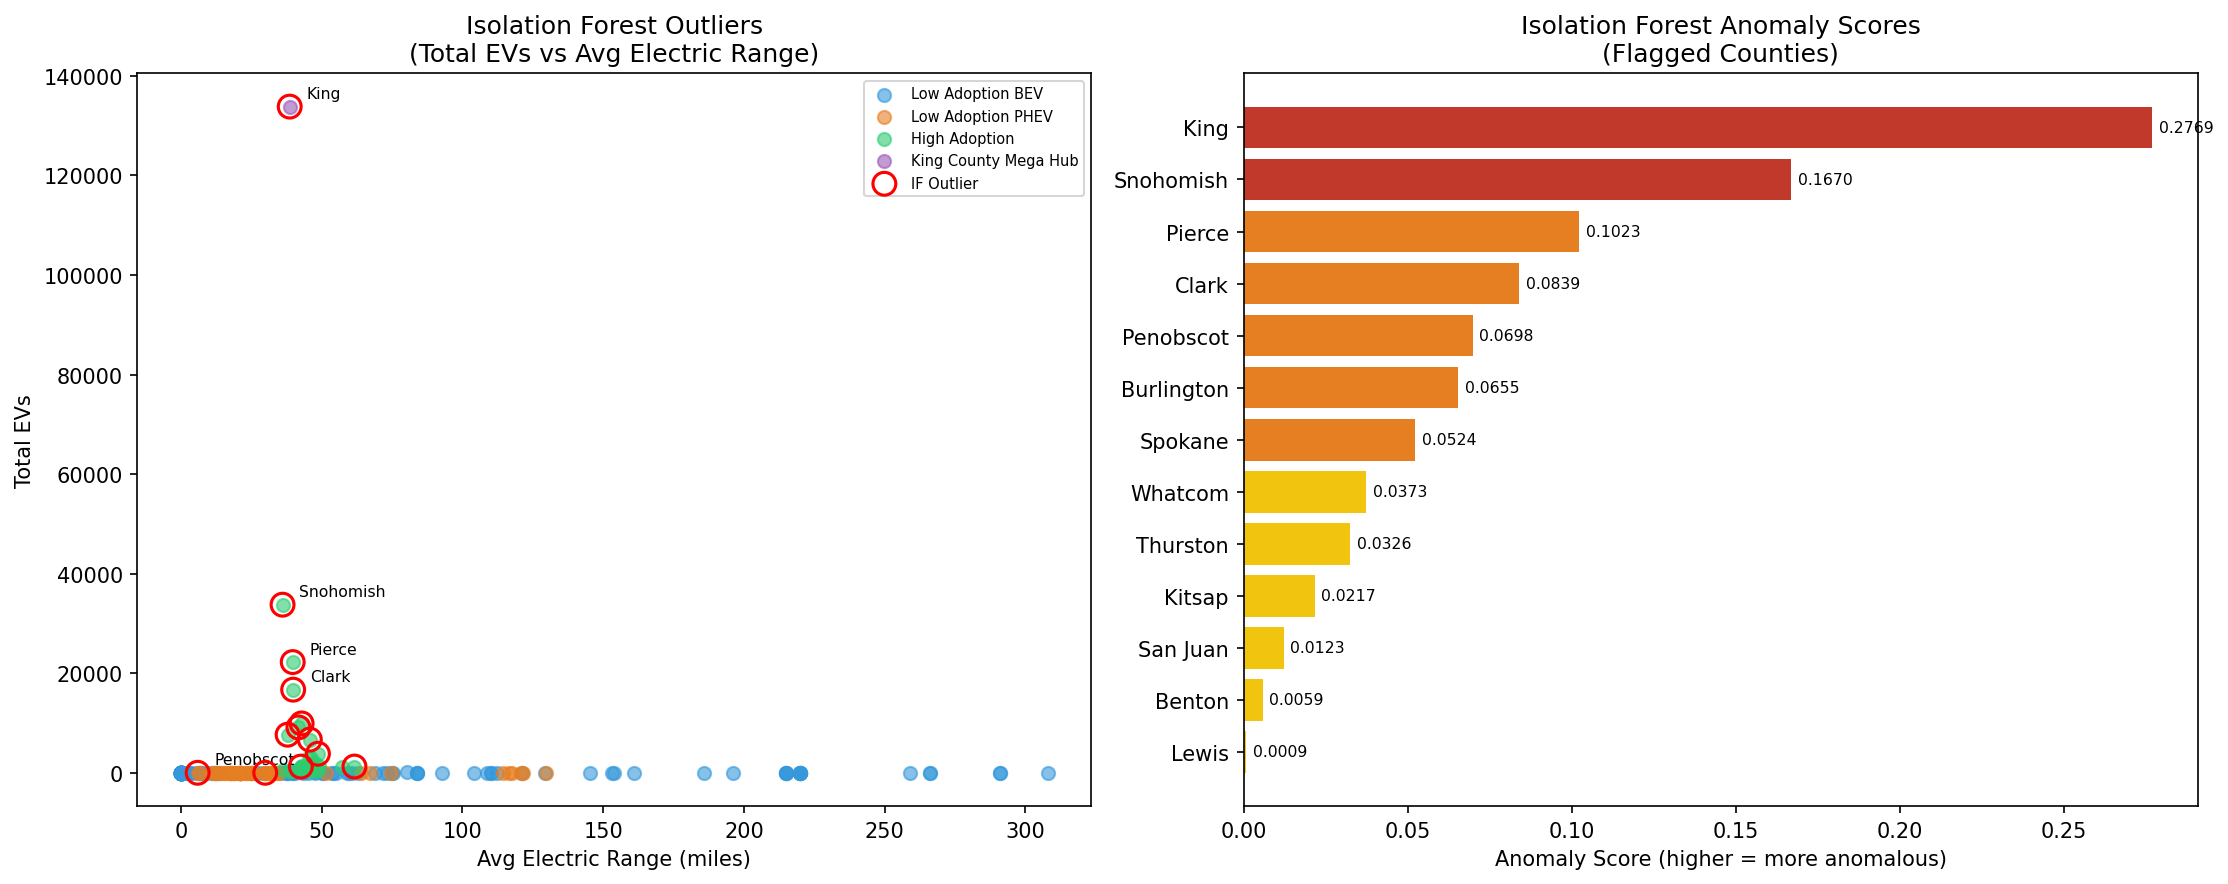

Figure saved: outlier_isolation_forest.png


In [8]:
# Merge IF results with cluster labels for colored scatter plot
if_plot_data = county_features.merge(
    county_clustered[['County', 'Cluster', 'Cluster_Label']], on='County', how='left'
)

cluster_colors = {
    'Low Adoption BEV': '#3498db',
    'Low Adoption PHEV': '#e67e22',
    'High Adoption': '#2ecc71',
    'King County Mega Hub': '#9b59b6'
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left plot: Total_EVs vs Avg_Electric_Range, colored by cluster, outliers marked
for label, color in cluster_colors.items():
    mask = if_plot_data['Cluster_Label'] == label
    axes[0].scatter(
        if_plot_data[mask]['Avg_Electric_Range'],
        if_plot_data[mask]['Total_EVs'],
        c=color, label=label, alpha=0.6, s=40
    )

# Highlight Isolation Forest outliers with red ring
outlier_mask = if_plot_data['IF_Outlier'] == True
axes[0].scatter(
    if_plot_data[outlier_mask]['Avg_Electric_Range'],
    if_plot_data[outlier_mask]['Total_EVs'],
    facecolors='none', edgecolors='red', linewidths=1.5, s=120, label='IF Outlier', zorder=5
)

# Label top 5 outliers by IF_Score
for _, row in if_outliers.head(5).iterrows():
    row_data = if_plot_data[if_plot_data['County'] == row['County']].iloc[0]
    axes[0].annotate(row['County'],
                     xy=(row_data['Avg_Electric_Range'], row_data['Total_EVs']),
                     xytext=(8, 4), textcoords='offset points', fontsize=7.5)

axes[0].set_xlabel('Avg Electric Range (miles)')
axes[0].set_ylabel('Total EVs')
axes[0].set_title('Isolation Forest Outliers\n(Total EVs vs Avg Electric Range)')
axes[0].legend(fontsize=7, loc='upper right')

# Right plot: IF anomaly scores bar chart — top 13 flagged counties
axes[1].barh(if_outliers['County'][::-1], if_outliers['IF_Score'][::-1],
             color=['#c0392b' if s > 0.15 else '#e67e22' if s > 0.05 else '#f1c40f'
                    for s in if_outliers['IF_Score'][::-1]])
axes[1].set_xlabel('Anomaly Score (higher = more anomalous)')
axes[1].set_title('Isolation Forest Anomaly Scores\n(Flagged Counties)')
for i, (_, row) in enumerate(if_outliers[::-1].iterrows()):
    axes[1].text(row['IF_Score'] + 0.002, i, f"{row['IF_Score']:.4f}", va='center', fontsize=7.5)

plt.tight_layout()
plt.savefig('outputs/figures/outlier_isolation_forest.png', bbox_inches='tight')
plt.show()
print("Figure saved: outlier_isolation_forest.png")

In [9]:
# Fit Local Outlier Factor — measures how isolated each county is relative to its neighbors
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
lof_labels = lof.fit_predict(X)
lof_scores = -lof.negative_outlier_factor_

county_features['LOF_Score'] = lof_scores
county_features['LOF_Outlier'] = lof_labels == -1

n_lof = county_features['LOF_Outlier'].sum()
print(f"LOF flagged {n_lof} counties as anomalies ({n_lof/len(county_features)*100:.1f}%)")
print()

lof_outliers = county_features[county_features['LOF_Outlier']][['County', 'Total_EVs', 'BEV_Proportion', 'Avg_Electric_Range', 'Unique_Makes', 'LOF_Score']].sort_values('LOF_Score', ascending=False)
print("LOF flagged counties (most anomalous first):")
print(lof_outliers.to_string(index=False))

king_lof = county_features[county_features['County'] == 'King'][['LOF_Score', 'LOF_Outlier']].values[0]
print(f"\nKing County — Flagged: {king_lof[1]} | LOF Score: {king_lof[0]:.4f}")

LOF flagged 13 counties as anomalies (5.3%)

LOF flagged counties (most anomalous first):
        County  Total_EVs  BEV_Proportion  Avg_Electric_Range  Unique_Makes  LOF_Score
     Clackamas          5          1.0000               47.60             4  19.100950
          King     133815          0.8183               38.69            44  13.379227
          Lake          7          0.8571                3.29             3  12.413781
San Bernardino          6          0.8333                5.33             3   9.795472
       Alameda          9          0.8889                2.33             4   8.936004
         Duval          8          0.8750                2.62             6   7.968791
    Rockingham          4          1.0000                0.00             2   6.870329
    Washington          4          1.0000                0.00             2   6.826801
     Allegheny          2          1.0000                0.00             2   6.826796
       Norfolk          3          1.000

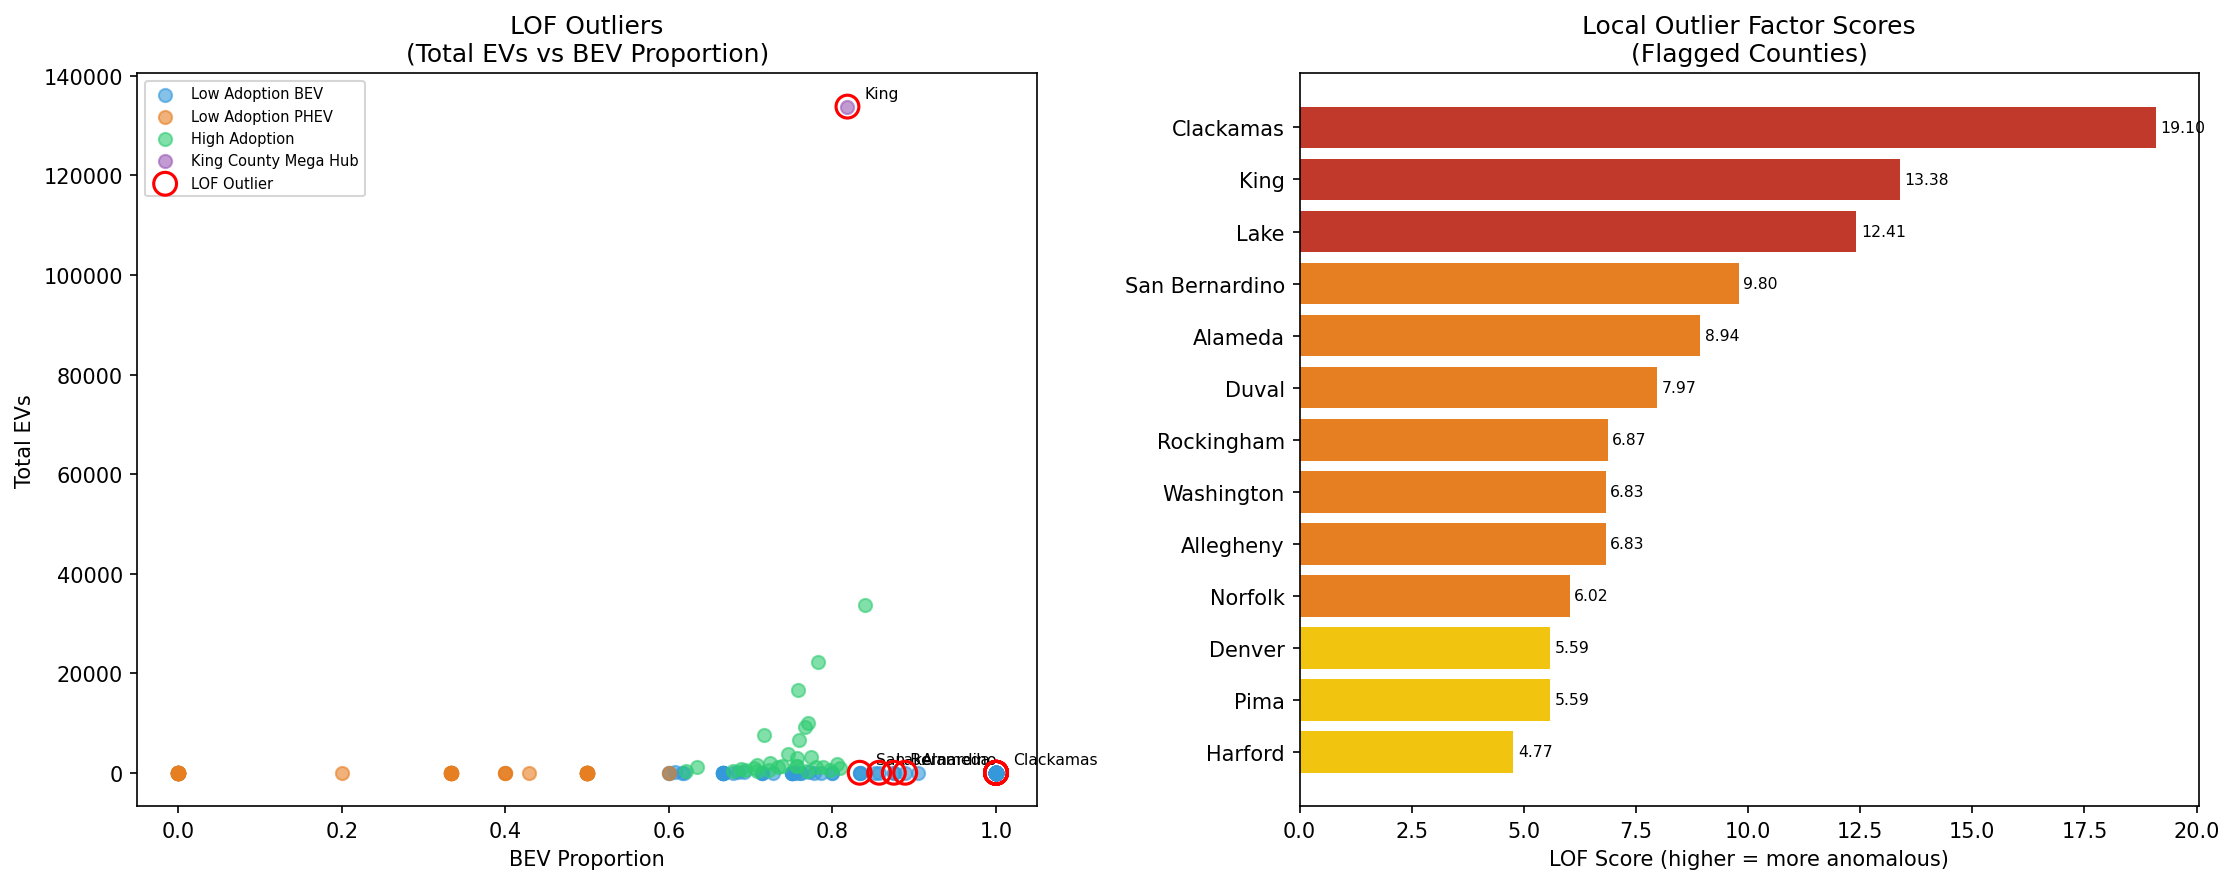

Figure saved: outlier_lof.png


In [10]:
# Merge LOF scores with cluster info for plotting
lof_plot_data = county_features.merge(
    county_clustered[['County', 'Cluster_Label']], on='County', how='left'
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left plot: scatter BEV_Proportion vs Total_EVs, LOF outliers highlighted
for label, color in cluster_colors.items():
    mask = lof_plot_data['Cluster_Label'] == label
    axes[0].scatter(
        lof_plot_data[mask]['BEV_Proportion'],
        lof_plot_data[mask]['Total_EVs'],
        c=color, label=label, alpha=0.6, s=40
    )

lof_mask = lof_plot_data['LOF_Outlier'] == True
axes[0].scatter(
    lof_plot_data[lof_mask]['BEV_Proportion'],
    lof_plot_data[lof_mask]['Total_EVs'],
    facecolors='none', edgecolors='red', linewidths=1.5, s=120, label='LOF Outlier', zorder=5
)

for _, row in lof_outliers.head(5).iterrows():
    row_data = lof_plot_data[lof_plot_data['County'] == row['County']].iloc[0]
    axes[0].annotate(row['County'],
                     xy=(row_data['BEV_Proportion'], row_data['Total_EVs']),
                     xytext=(8, 4), textcoords='offset points', fontsize=7.5)

axes[0].set_xlabel('BEV Proportion')
axes[0].set_ylabel('Total EVs')
axes[0].set_title('LOF Outliers\n(Total EVs vs BEV Proportion)')
axes[0].legend(fontsize=7, loc='upper left')

# Right plot: LOF scores for all flagged counties
axes[1].barh(lof_outliers['County'][::-1], lof_outliers['LOF_Score'][::-1],
             color=['#c0392b' if s > 10 else '#e67e22' if s > 6 else '#f1c40f'
                    for s in lof_outliers['LOF_Score'][::-1]])
axes[1].set_xlabel('LOF Score (higher = more anomalous)')
axes[1].set_title('Local Outlier Factor Scores\n(Flagged Counties)')
for i, (_, row) in enumerate(lof_outliers[::-1].iterrows()):
    axes[1].text(row['LOF_Score'] + 0.1, i, f"{row['LOF_Score']:.2f}", va='center', fontsize=7.5)

plt.tight_layout()
plt.savefig('outputs/figures/outlier_lof.png', bbox_inches='tight')
plt.show()
print("Figure saved: outlier_lof.png")

In [11]:
# Build a unified outlier summary across all four methods
outlier_summary = county_features[['County', 'Total_EVs', 'BEV_Proportion',
                                    'Avg_Electric_Range', 'Unique_Makes']].copy()

outlier_summary['IQR_Outlier'] = outlier_summary['County'].isin(
    total_evs_outliers['County'].tolist()
)
outlier_summary['ZScore_Outlier'] = outlier_summary['County'].isin(
    z_outliers['County'].tolist()
)
outlier_summary['IF_Outlier'] = county_features['IF_Outlier'].values
outlier_summary['LOF_Outlier'] = county_features['LOF_Outlier'].values

# Count how many methods flagged each county
outlier_summary['Methods_Flagged'] = (
    outlier_summary['IQR_Outlier'].astype(int) +
    outlier_summary['ZScore_Outlier'].astype(int) +
    outlier_summary['IF_Outlier'].astype(int) +
    outlier_summary['LOF_Outlier'].astype(int)
)

# Keep only counties flagged by at least one method
flagged = outlier_summary[outlier_summary['Methods_Flagged'] > 0].sort_values(
    'Methods_Flagged', ascending=False
)

# Save to CSV
flagged.to_csv('outputs/results/outlier_counties.csv', index=False)
print("Saved: outlier_counties.csv")
print(f"Total counties flagged by at least one method: {len(flagged)}")
print()

# Cross-method agreement summary
print("Cross-method agreement:")
print(flagged['Methods_Flagged'].value_counts().sort_index(ascending=False).to_string())
print()

# Counties flagged by ALL 4 methods
all4 = flagged[flagged['Methods_Flagged'] == 4][['County', 'Total_EVs', 'BEV_Proportion', 'Methods_Flagged']]
print("Counties flagged by ALL 4 methods:")
print(all4.to_string(index=False))

# Counties flagged by 3 methods
three = flagged[flagged['Methods_Flagged'] == 3][['County', 'Total_EVs', 'BEV_Proportion', 'Methods_Flagged']]
print("\nCounties flagged by 3 methods:")
print(three.to_string(index=False))

Saved: outlier_counties.csv
Total counties flagged by at least one method: 70

Cross-method agreement:
Methods_Flagged
4     1
3     8
2     4
1    57

Counties flagged by ALL 4 methods:
County  Total_EVs  BEV_Proportion  Methods_Flagged
  King     133815          0.8183                4

Counties flagged by 3 methods:
   County  Total_EVs  BEV_Proportion  Methods_Flagged
  Spokane       7652          0.7162                3
   Benton       3827          0.7452                3
    Clark      16694          0.7576                3
Snohomish      33766          0.8398                3
 Thurston       9911          0.7705                3
   Kitsap       9116          0.7666                3
   Pierce      22238          0.7824                3
  Whatcom       6664          0.7586                3


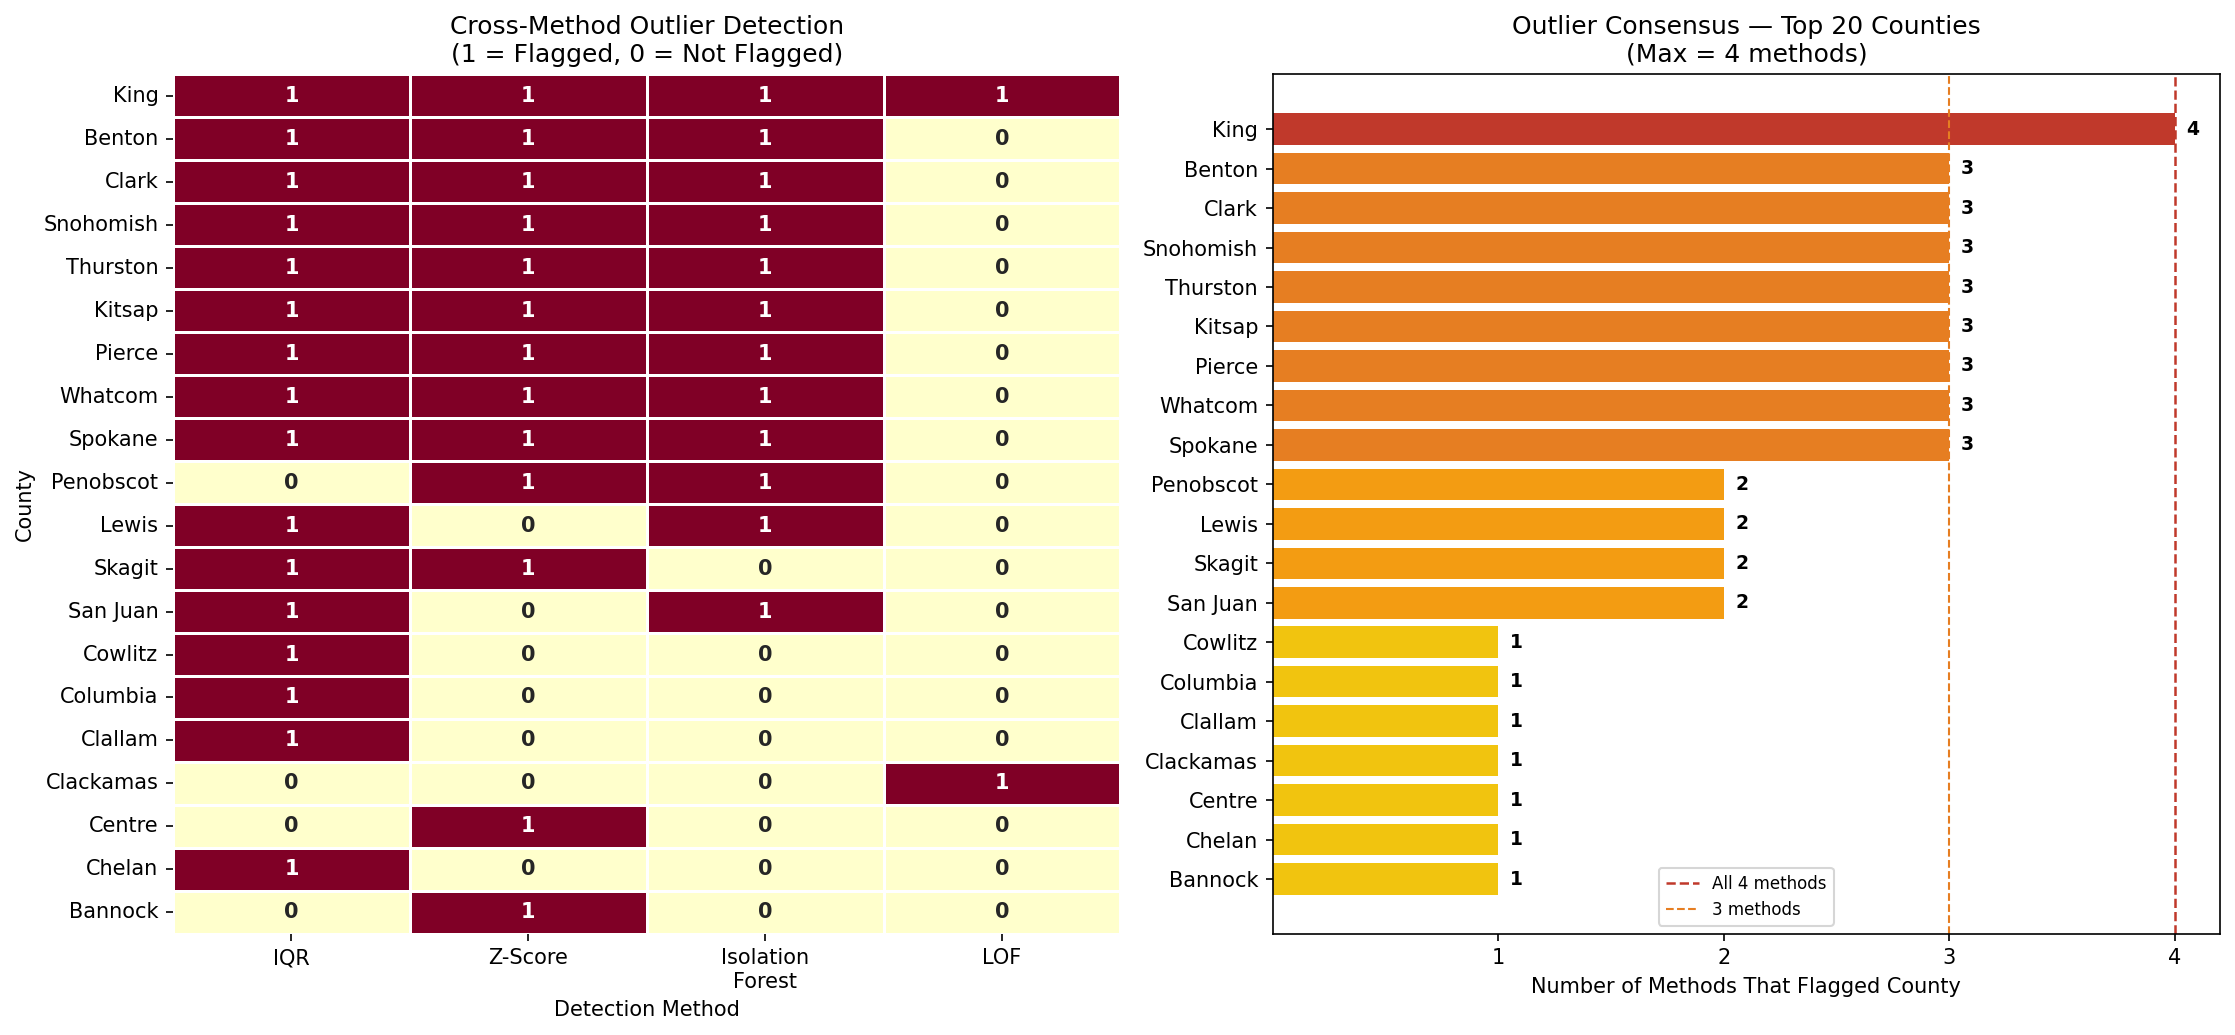

Figure saved: outlier_consensus.png


In [12]:
# Final cross-method comparison heatmap
top_flagged = flagged.sort_values('Methods_Flagged', ascending=False).head(20)

method_cols = ['IQR_Outlier', 'ZScore_Outlier', 'IF_Outlier', 'LOF_Outlier']
heatmap_data = top_flagged.set_index('County')[method_cols].astype(int)
heatmap_data.columns = ['IQR', 'Z-Score', 'Isolation\nForest', 'LOF']

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Left: binary heatmap showing which methods flagged which counties
sns.heatmap(heatmap_data, ax=axes[0], cmap='YlOrRd', linewidths=0.5,
            annot=True, fmt='d', cbar=False,
            annot_kws={'size': 10, 'weight': 'bold'})
axes[0].set_title('Cross-Method Outlier Detection\n(1 = Flagged, 0 = Not Flagged)')
axes[0].set_xlabel('Detection Method')
axes[0].tick_params(axis='y', rotation=0)
axes[0].tick_params(axis='x', rotation=0)

# Right: Methods_Flagged bar chart for top 20
colors_bar = ['#c0392b' if m == 4 else '#e67e22' if m == 3 else '#f39c12' if m == 2 else '#f1c40f'
              for m in top_flagged['Methods_Flagged']]
axes[1].barh(top_flagged['County'][::-1], top_flagged['Methods_Flagged'][::-1],
             color=colors_bar[::-1])
axes[1].axvline(x=4, color='#c0392b', linestyle='--', linewidth=1.2, label='All 4 methods')
axes[1].axvline(x=3, color='#e67e22', linestyle='--', linewidth=1.0, label='3 methods')
axes[1].set_xlabel('Number of Methods That Flagged County')
axes[1].set_title('Outlier Consensus — Top 20 Counties\n(Max = 4 methods)')
axes[1].set_xticks([1, 2, 3, 4])
axes[1].legend(fontsize=8)
for i, (_, row) in enumerate(top_flagged[::-1].iterrows()):
    axes[1].text(row['Methods_Flagged'] + 0.05, i, str(int(row['Methods_Flagged'])),
                 va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('outputs/figures/outlier_consensus.png', bbox_inches='tight')
plt.show()
print("Figure saved: outlier_consensus.png")

In [13]:
# Final findings summary for the outlier detection module
print("=" * 60)
print("OUTLIER DETECTION — KEY FINDINGS SUMMARY")
print("=" * 60)

print(f"""
PRIMARY QUESTION (EQ3):
Is King County a formal statistical outlier?
Answer: YES — flagged by ALL 4 detection methods.
  - IQR:               Upper fence = 11 EVs. King = 133,815.
  - Z-Score:           14.79 std deviations above mean on Total_EVs.
  - Isolation Forest:  Anomaly score 0.2769 (highest in dataset).
  - LOF:               Score 13.38 (2nd highest, behind Clackamas).

SECONDARY FINDINGS:
  - 8 counties flagged by 3 methods: Snohomish, Pierce, Clark,
    Thurston, Kitsap, Whatcom, Benton, Spokane.
    All are legitimate high-adoption Washington State counties.

  - IQR flags 47 counties on Total_EVs because the distribution
    is so right-skewed — the upper fence is only 11 EVs.
    This reflects extreme concentration, not data error.

  - LOF top anomaly is Clackamas (score 19.10): only 5 EVs but
    100% BEV and high range — locally unusual among neighbors.

  - Isolation Forest flagged Penobscot and Burlington (tiny
    out-of-state counties with 100% PHEV, 0 electric range).

METHOD AGREEMENT:
  - 4 methods: 1 county  (King)
  - 3 methods: 8 counties (high-adoption WA counties)
  - 2 methods: 4 counties
  - 1 method:  57 counties

OUTPUT FILES:
  - outputs/results/outlier_counties.csv
  - outputs/figures/outlier_iqr.png
  - outputs/figures/outlier_zscore.png
  - outputs/figures/outlier_isolation_forest.png
  - outputs/figures/outlier_lof.png
  - outputs/figures/outlier_consensus.png
""")
print("=" * 60)
print("Module 05 complete.")
print("=" * 60)

OUTLIER DETECTION — KEY FINDINGS SUMMARY

PRIMARY QUESTION (EQ3):
Is King County a formal statistical outlier?
Answer: YES — flagged by ALL 4 detection methods.
  - IQR:               Upper fence = 11 EVs. King = 133,815.
  - Z-Score:           14.79 std deviations above mean on Total_EVs.
  - Isolation Forest:  Anomaly score 0.2769 (highest in dataset).
  - LOF:               Score 13.38 (2nd highest, behind Clackamas).

SECONDARY FINDINGS:
  - 8 counties flagged by 3 methods: Snohomish, Pierce, Clark,
    Thurston, Kitsap, Whatcom, Benton, Spokane.
    All are legitimate high-adoption Washington State counties.

  - IQR flags 47 counties on Total_EVs because the distribution
    is so right-skewed — the upper fence is only 11 EVs.
    This reflects extreme concentration, not data error.

  - LOF top anomaly is Clackamas (score 19.10): only 5 EVs but
    100% BEV and high range — locally unusual among neighbors.

  - Isolation Forest flagged Penobscot and Burlington (tiny
    out-of-s